In [ ]:
# # # In colab, uncomment
# %%bash

# set -euo pipefail

# BASE_URL="https://raw.githubusercontent.com/Inkln/CV-HSE-MIPT-Course-2026-spring/refs/heads/main/lesson_9"
# REPO_URL="https://github.com/Inkln/CV-HSE-MIPT-Course-2026-spring.git"
# SUBDIR="lesson_9"

# FILES=(
#   ".python-version"
#   "pyproject.toml"
#   "uv.lock"
# )

# for file in "${FILES[@]}"; do
#   echo "Downloading $file..."
#   curl -fsSL -o "$file" "$BASE_URL/$file"
# done

# if ! command -v uv >/dev/null 2>&1; then
#   echo "Error: uv is not installed or not in PATH." >&2
#   exit 1
# fi

# export UV_PROJECT_ENVIRONMENT="/usr/"
# echo "Installing dependencies into the global Python environment..."
# uv sync --locked 

# # Download assets folder using sparse checkout
# echo "Downloading assets folder..."
# TMP_DIR="$(mktemp -d)"

# git clone --depth=1 --filter=blob:none --sparse "$REPO_URL" "$TMP_DIR"
# cd "$TMP_DIR"
# git sparse-checkout set "$SUBDIR/assets"

# cd - >/dev/null
# mkdir -p assets
# cp -r "$TMP_DIR/$SUBDIR/assets/"* ./assets/

# rm -rf "$TMP_DIR"

# echo "Done."

# Лекция 9: Компьютерное зрение
## Generative modeling: Autoregressive models & Diffusion. Часть 1

**Преподаватель:** Шевченко Елена

**Аудитория:** МФТИ

---

## Содержание

1. Метрики
   1. Почему оценивать генерацию трудно
   2. FID
   3. Precision & Recall
   4. Text-to-image: CLIPScore, VQAScore
   5. VLM-as-a-judge
   6. Люди и арены
2. Autoregressive
   1. Постановка задачи
   2. PixelCNN — идея
   3. От пикселей к токенам
   4. VAR
   5. Switti
   6. Infinity
   7. Современные AR-модели (2024–2026)
3. Diffusion
   1. Зачем ещё один класс генеративных моделей
   2. Forward process: зашумление
   3. Reverse process и что мы учим
   4. Сэмплирование: от DDPM к DDIM
   5. Параметризации: что именно предсказывает сеть
   6. Архитектура: как устроена $\epsilon_\theta(x_t, t)$
   7. Условная генерация: classifier guidance → CFG
   8. Latent Diffusion и cross-attention с текстом
   9. Stable Diffusion: 1.x → 2 → SDXL
   10. Итоги и мостик к лекции 10

Часть 3 (Diffusion) — в ноутбуке `9-2 Diffusion.ipynb`.

---

# Метрики

## 0. Почему оценивать генерацию трудно

- Нет единственного правильного ответа (GT): одному классу или промпту соответствует бесконечно много хороших картинок
- Две независимые оси:
  - **качество / реалистичность** (fidelity) — насколько каждая картинка похожа на настоящую
  - **разнообразие / покрытие** (diversity) — насколько набор сэмплов покрывает распределение реальных данных
- Для text-to-image есть третья ось — **соответствие тексту** (промпту)
- Метрики бывают двух типов:
  - **distribution-level** — сравнивают два набора картинок (реальные vs сгенерированные): FID, Precision/Recall, VLM-aaj
  - **per-sample** — оценивают одну картинку (+ промпт): CLIPScore, VLM-aaj
- Каждая метрика измеряет что-то одно, поэтому на практике смотрят на несколько метрик сразу + на оценки людей

## 1. FID (Fréchet Inception Distance)

[Heusel et al., 2017](https://arxiv.org/abs/1706.08500)

*Идея*
- Прогоняем реальные и сгенерированные картинки через [Inception-v3](https://arxiv.org/pdf/1512.00567) и берём признаки с последнего pooling-слоя (в стандартной реализации — 2048-мерный вектор)
- По каждому набору оцениваем среднее и ковариацию → две гауссианы: $\mathcal{N}(\mu_r, \Sigma_r)$ для реальных и $\mathcal{N}(\mu_g, \Sigma_g)$ для сгенерированных
- Считаем расстояние Фреше между ними:

$$\text{FID} = \|\mu_r-\mu_g\|^2 + \mathrm{Tr}\big(\Sigma_r+\Sigma_g-2(\Sigma_r\Sigma_g)^{1/2}\big)$$

- Меньше = лучше
- В статье показано, что FID монотонно растёт при добавлении шума, блюра и артефактов

### Подводные камни

1. **Смещение от числа сэмплов.** FID зависит от N, причём величина смещения зависит от модели → сравнивать модели только при одинаковом N. 
2. **Ресайз и JPEG.** Детали реализации меняют FID на единицы.
3. **FID «накручивается» через ImageNet-классы.** 
4. **Признаки Inception устарели.** [Stein et al., 2023](https://arxiv.org/abs/2306.04675) рекомендуют DINOv2-ViT-L/14 ($\text{FD}_\text{DINOv2}$); также встречается $\text{FID}_\text{CLIP}$

*Inception Score* (Salimans et al., 2016): $\text{IS}=\exp\,\mathbb{E}_x\,\mathrm{KL}(p(y|x)\,\|\,p(y))$ — тоже завязан на ImageNet-классы, сами авторы называли его «rough guide», сейчас почти не используется.

Код ниже — реализация FID (адаптация torchmetrics).

In [ ]:
# source https://github.com/Lightning-AI/torchmetrics/blob/master/src/torchmetrics/image/fid.py
import torch

from torch import Tensor
from torch_fidelity.feature_extractor_inceptionv3 import FeatureExtractorInceptionV3


def compute_fid(mu1: Tensor, sigma1: Tensor, mu2: Tensor, sigma2: Tensor) -> Tensor:
    r"""Compute adjusted version of `Fid Score`_.

    The Frechet Inception Distance between two multivariate Gaussians X_x ~ N(mu_1, sigm_1)
    and X_y ~ N(mu_2, sigm_2) is d^2 = ||mu_1 - mu_2||^2 + Tr(sigm_1 + sigm_2 - 2*sqrt(sigm_1*sigm_2)).

    Args:
        mu1: mean of activations calculated on predicted (x) samples
        sigma1: covariance matrix over activations calculated on predicted (x) samples
        mu2: mean of activations calculated on target (y) samples
        sigma2: covariance matrix over activations calculated on target (y) samples

    Returns:
        Scalar value of the distance between sets.

    """
    a = (mu1 - mu2).square().sum(dim=-1)
    b = sigma1.trace() + sigma2.trace()
    c = torch.linalg.eigvals(sigma1 @ sigma2).sqrt().real.sum(dim=-1)

    return a + b - 2 * c


class FrechetInceptionDistance:
    def __init__(self) -> None:
        self.normalize = False
        self.antialias = True
        self.num_features = 2048

        self.inception = FeatureExtractorInceptionV3(
            name="inception-v3-compat",
            features_list=[str(self.num_features)],
            feature_extractor_weights_path=None,
            antialias=self.antialias,
        )

        self.mx_num_feats = (self.num_features, self.num_features)
        
        self.real_features_sum = torch.zeros(self.num_features).double()
        self.real_features_cov_sum = torch.zeros(self.mx_num_feats).double()
        self.real_features_num_samples = torch.tensor(0).long()

        self.fake_features_sum = torch.zeros(self.num_features).double()
        self.fake_features_cov_sum = torch.zeros(self.mx_num_feats).double() 
        self.fake_features_num_samples = torch.tensor(0).long()

    def update(self, imgs: Tensor, real: bool) -> None:
        """Update the state with extracted features.

        Args:
            imgs: Input img tensors to evaluate. If used custom feature extractor please
                make sure dtype and size is correct for the model.
            real: Whether given image is real or fake.

        """
        imgs = (imgs * 255).byte() if self.normalize else imgs
        features = self.inception(imgs)[0]
        self.orig_dtype = features.dtype
        features = features.double()

        if features.dim() == 1:
            features = features.unsqueeze(0)
        if real:
            self.real_features_sum += features.sum(dim=0)
            self.real_features_cov_sum += features.t().mm(features)
            self.real_features_num_samples += imgs.shape[0]
        else:
            self.fake_features_sum += features.sum(dim=0)
            self.fake_features_cov_sum += features.t().mm(features)
            self.fake_features_num_samples += imgs.shape[0]

    def compute(self) -> Tensor:
        """Calculate FID score based on accumulated extracted features from the two distributions."""
        if self.real_features_num_samples < 2 or self.fake_features_num_samples < 2:
            raise RuntimeError("More than one sample is required for both the real and fake distributed to compute FID")
        mean_real = (self.real_features_sum / self.real_features_num_samples).unsqueeze(0)
        mean_fake = (self.fake_features_sum / self.fake_features_num_samples).unsqueeze(0)

        cov_real_num = self.real_features_cov_sum - self.real_features_num_samples * mean_real.t().mm(mean_real)
        cov_real = cov_real_num / (self.real_features_num_samples - 1)
        cov_fake_num = self.fake_features_cov_sum - self.fake_features_num_samples * mean_fake.t().mm(mean_fake)
        cov_fake = cov_fake_num / (self.fake_features_num_samples - 1)
        return compute_fid(mean_real.squeeze(0), cov_real, mean_fake.squeeze(0), cov_fake).to(self.orig_dtype)

    def reset(self) -> None:
        """Reset metric states."""
        self.real_features_sum = torch.zeros(self.num_features).double()
        self.real_features_cov_sum = torch.zeros(self.mx_num_feats).double()
        self.real_features_num_samples = torch.tensor(0).long()

        self.fake_features_sum = torch.zeros(self.num_features).double()
        self.fake_features_cov_sum = torch.zeros(self.mx_num_feats).double() 
        self.fake_features_num_samples = torch.tensor(0).long()


########
fid = FrechetInceptionDistance()

imgs_dist1 = torch.randint(0, 200, (50, 3, 299, 299), dtype=torch.uint8)
imgs_dist2 = torch.randint(100, 255, (50, 3, 299, 299), dtype=torch.uint8)

fid.update(imgs_dist1, real=True)
fid.update(imgs_dist2, real=False)
fid.compute()

tensor(23.9406)

## 2. Precision & Recall для генеративных моделей

*Мотивация*
- FID сжимает fidelity и diversity в одно число: mode collapse и мусорные сэмплы могут дать одинаковый FID

*Идея* ([Sajjadi et al., 2018](https://arxiv.org/abs/1806.00035); практичная версия — [Kynkäänniemi et al., 2019](https://arxiv.org/abs/1904.06991))
- Оцениваем «многообразие» каждого распределения в пространстве признаков как объединение шаров вокруг точек радиусом до k-го соседа
- В статье: k=3, по 50k сэмплов, признаки VGG-16 после второго FC-слоя (Inception даёт похожий результат)
- $\text{precision}$ — доля сгенерированных точек, попавших внутрь многообразия реальных → качество
- $\text{recall}$ — доля реальных точек внутри многообразия сгенерированных → покрытие / разнообразие

![precision-recall](./assets/precision-recall.png)

*Недостатки*
- Чувствительность к выбросам: один outlier раздувает шар
- Гиперпараметр k
- → [Naeem et al., 2020](https://arxiv.org/abs/2002.09797) предлагают density & coverage

In [4]:
# adapted from https://github.com/toshas/torch-fidelity

def _cdist_part(features_1, features_2, batch_size=10000):
    """Row-batched pairwise L2 distances (features_1 rows vs all of features_2)."""
    dists = []
    for feat2_batch in features_2.split(batch_size):
        dists.append(torch.cdist(features_1, feat2_batch).cpu())
    return torch.cat(dists, dim=1)


def _cdist_full(features_1, features_2, batch_size=10000):
    """Full pairwise L2 distance matrix, computed in blocks to limit GPU memory."""
    dists = []
    for feat1_batch in features_1.split(batch_size):
        dists_batch = []
        for feat2_batch in features_2.split(batch_size):
            dists_batch.append(torch.cdist(feat1_batch, feat2_batch).cpu())
        dists.append(torch.cat(dists_batch, dim=1))
    return torch.cat(dists, dim=0)


# faster, more RAM
def _precision_recall_full(features_1, features_2, neighborhood=3, batch_size=10000):
    dist_nn_1 = _cdist_full(features_1, features_1, batch_size).kthvalue(neighborhood + 1).values
    dist_nn_2 = _cdist_full(features_2, features_2, batch_size).kthvalue(neighborhood + 1).values
    dist_2_1 = _cdist_full(features_2, features_1, batch_size)
    dist_1_2 = dist_2_1.T
    recall = (dist_2_1 <= dist_nn_1).any(dim=1).float().mean().item()
    precision = (dist_1_2 <= dist_nn_2).any(dim=1).float().mean().item()
    return precision, recall


# slower, less RAM
def _precision_recall_part(features_1, features_2, neighborhood=3, batch_size=10000):
    # Recall: for each real sample, is it inside any generated sample's ball?
    dist_nn_1 = []
    for feat_1_batch in features_1.split(batch_size):
        dist_nn_1.append(_cdist_part(feat_1_batch, features_1, batch_size).kthvalue(neighborhood + 1).values)
    dist_nn_1 = torch.cat(dist_nn_1)
    recall = []
    for feat_2_batch in features_2.split(batch_size):
        dist_2_1_batch = _cdist_part(feat_2_batch, features_1, batch_size)
        recall.append((dist_2_1_batch <= dist_nn_1).any(dim=1).float())
    recall = torch.cat(recall).mean().item()
    # Precision: for each generated sample, is it inside any real sample's ball?
    dist_nn_2 = []
    for feat_2_batch in features_2.split(batch_size):
        dist_nn_2.append(_cdist_part(feat_2_batch, features_2, batch_size).kthvalue(neighborhood + 1).values)
    dist_nn_2 = torch.cat(dist_nn_2)
    precision = []
    for feat_1_batch in features_1.split(batch_size):
        dist_1_2_batch = _cdist_part(feat_1_batch, features_2, batch_size)
        precision.append((dist_1_2_batch <= dist_nn_2).any(dim=1).float())
    precision = torch.cat(precision).mean().item()
    return precision, recall


def precision_recall(features_generated, features_real, neighborhood=3, batch_size=10000, save_cpu_ram=False):
    """
    Compute Precision, Recall, and F-score between two sets of feature vectors.

    Args:
        features_generated: Tensor (N, D) — generated sample features.
        features_real:      Tensor (M, D) — real sample features.
        neighborhood:       Number of nearest neighbors for manifold estimation (default 3).
        batch_size:         Block size for batched distance computation (default 10000).
        save_cpu_ram:       If True, use a slower but more memory-efficient algorithm.

    Returns:
        (precision, recall, f_score) — all floats in [0, 1].
    """
    assert features_generated.dim() == 2 and features_real.dim() == 2
    assert features_generated.shape[1] == features_real.shape[1]

    fn = _precision_recall_part if save_cpu_ram else _precision_recall_full
    precision, recall = fn(features_generated, features_real, neighborhood, batch_size)
    f_score = 2 * precision * recall / max(1e-5, precision + recall)
    return precision, recall, f_score


features_generated = torch.randn(1000, 100)
features_real = torch.randn(500, 100)

precision, recall, f_score = precision_recall(features_generated, features_real)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F-score: {f_score:.4f}")

Precision: 0.5680
Recall: 0.5960
F-score: 0.5817


## 3. Text-to-image: соответствие тексту

### CLIPScore

[Hessel et al., 2021](https://arxiv.org/abs/2104.08718)

$$\text{CLIP-S}(c,v)=w\cdot\max(\cos(c,v),0)$$

- $c$ — CLIP-эмбеддинг текста, $v$ — CLIP-эмбеддинг картинки
- $w=2.5$ — для читаемости шкалы
- Reference-free: эталонные картинки не нужны
- Слабость: текстовый энкодер CLIP ведёт себя как «мешок слов» — композицию («собака слева от кошки») не различает

### VQAScore

[Lin et al., 2024](https://arxiv.org/abs/2404.01291)

- Спрашиваем VLM «Does this figure show '{text}'?» и берём $P(\text{Yes})$

### Бенчмарки и IQA-модели

Есть специализированные бенчмарки и IQA-модели: WISE ([arXiv](https://arxiv.org/abs/2503.07265), [GitHub](https://github.com/PKU-YuanGroup/WISE)) — знание о мире в промптах; Q-SiT ([arXiv](https://arxiv.org/abs/2503.09197), [GitHub](https://github.com/zzc-1998/Q-SiT)) и DeQA-Score ([arXiv](https://arxiv.org/abs/2501.11561), [GitHub](https://github.com/zhiyuanyou/DeQA-Score)) — VLM, дообученные оценивать качество картинки.

## 4. VLM-as-a-judge (VLM-AAJ)

*Идея*
- Просим сильную VLM оценить картинку (+ промпт) по рубрике — так, как это сделал бы асессор

### Режимы

- **Standalone** — оценка по шкале (например, 0–10); отдельно semantic consistency (соответствие промпту) и perceptual quality (визуальное качество), как в [VIEScore](https://arxiv.org/abs/2312.14867)
- **Side-by-side / pairwise** — две картинки на один промпт, выбор лучшей или ничья

### Как писать промпт-рубрику

- Критерии — явно
- Просить объяснение (rationale) **перед** оценкой
- Фиксированный формат ответа (JSON)
- temperature 0

### Смещения судьи

[Zheng et al., 2023](https://arxiv.org/abs/2306.05685) — для LLM, те же эффекты наблюдаются у VLM:
- **Position bias** — в pairwise-режиме GPT-4 давал согласованный ответ при смене порядка только в 65% случаев
- **Verbosity bias** — предпочтение более многословных ответов
- **Self-enhancement** — модель любит «своё»
- Лечение position bias: прогонять пару в обоих порядках (A/B и B/A), несогласованные ответы считать ничьёй

### Насколько судье можно верить

- GPT-4 согласен с людьми в 85% случаев на не-ничьих, люди между собой — 81% (Zheng et al., 2023, Table 5)
- Для T2I (VIEScore): корреляция Спирмена с людьми ≈0.4–0.46 у GPT-4v/4o против ≈0.46 человек-человек и ≈0 у CLIPScore
- [MJ-Bench](https://arxiv.org/abs/2407.04842) — бенчмарк самих VLM-судей (alignment, safety, quality, bias); часть открытых VLM чувствительна к порядку картинок в паре

### Когда уместен

- Быстрые A/B-сравнения моделей и чекпойнтов
- Фильтрация данных
- Reward model
- **Не** уместен: финальные заявления о качестве без людей

Код ниже — пример SBS-запроса к VLM.

In [ ]:
# VLM-AAJ SBS
import os
import io
import json
import base64
from typing import Literal, Optional, Dict, Any

import requests
from PIL import Image


OpenRouterWinner = Literal["A", "B"]


class OpenRouterVLMJudgeError(Exception):
    pass


def pil_to_data_url(image: Image.Image, format: str = "PNG") -> str:
    """
    Convert PIL.Image to data URL suitable for OpenRouter image input.
    """
    buffer = io.BytesIO()

    image.save(buffer, format=format)
    image_bytes = buffer.getvalue()

    mime = "image/png" if format.upper() == "PNG" else f"image/{format.lower()}"
    b64 = base64.b64encode(image_bytes).decode("utf-8")
    return f"data:{mime};base64,{b64}"


def extract_text_content(message_content: Any) -> str:
    """
    OpenRouter responses usually return message.content as a string,
    but some providers may return structured content. This helper
    makes the parsing more robust.
    """
    if isinstance(message_content, str):
        return message_content

    if isinstance(message_content, list):
        parts = []
        for item in message_content:
            if isinstance(item, dict):
                if item.get("type") == "text" and "text" in item:
                    parts.append(item["text"])
        return "\n".join(parts).strip()

    return str(message_content)


def parse_winner_from_response(text: str) -> Dict[str, Any]:
    """
    Expect strict JSON like:
    {
      "winner": "A",
      "reason": "..."
    }
    """
    text = text.strip()

    try:
        data = json.loads(text)
        winner = data.get("winner")
        if winner not in ("A", "B"):
            raise OpenRouterVLMJudgeError(f"Invalid winner in JSON: {winner!r}")
        return data
    except json.JSONDecodeError:
        pass

    start = text.find("{")
    end = text.rfind("}")
    if start != -1 and end != -1 and end > start:
        candidate = text[start:end + 1]
        try:
            data = json.loads(candidate)
            winner = data.get("winner")
            if winner not in ("A", "B"):
                raise OpenRouterVLMJudgeError(f"Invalid winner in JSON block: {winner!r}")
            return data
        except json.JSONDecodeError:
            pass

    upper = text.upper()
    if '"WINNER": "A"' in upper or "WINNER: A" in upper or upper == "A":
        return {"winner": "A", "reason": text}
    if '"WINNER": "B"' in upper or "WINNER: B" in upper or upper == "B":
        return {"winner": "B", "reason": text}

    raise OpenRouterVLMJudgeError(
        f"Could not parse winner from model response: {text}"
    )


def judge_images_side_by_side(
    image_a: Image.Image,
    image_b: Image.Image,
    *,
    api_key: Optional[str] = None,
    model: str = "openai/gpt-4o",
    timeout: int = 60,
    return_full: bool = False,
) -> OpenRouterWinner | Dict[str, Any]:
    """
    Compare two PIL images using a VLM via OpenRouter and return the winner.

    Parameters
    ----------
    image_a : PIL.Image.Image
        First image
    image_b : PIL.Image.Image
        Second image
    api_key : str | None
        OpenRouter API key. If None, uses OPENROUTER_API_KEY env var.
    model : str
        Vision-capable model on OpenRouter
    timeout : int
        HTTP timeout in seconds
    return_full : bool
        If True, return parsed JSON with reason + raw response metadata

    Returns
    -------
    "A" or "B"
        Which image is better according to the model
    """
    api_key = api_key or os.getenv("OPENROUTER_API_KEY")
    if not api_key:
        raise ValueError(
            "OpenRouter API key not provided. Pass api_key=... "
            "or set OPENROUTER_API_KEY environment variable."
        )

    image_a_url = pil_to_data_url(image_a, format="PNG")
    image_b_url = pil_to_data_url(image_b, format="PNG")

    system_prompt = (
        "You are an expert visual judge. "
        "You compare two candidate images side-by-side and decide which one is better overall. "
        "Evaluate visual quality, composition, realism or stylization consistency, artifacts, "
        "clarity, aesthetics, and prompt-faithfulness when inferable. "
        "Be decisive. Do not output ties."
    )

    user_prompt = (
        "Compare two images:\n"
        "- Image A = first image\n"
        "- Image B = second image\n\n"
        "Choose the better image overall.\n"
        "Return STRICT JSON only in the following format:\n"
        '{"winner":"A","reason":"short explanation"}\n'
        'or {"winner":"B","reason":"short explanation"}\n'
        "No markdown. No extra text."
    )

    payload = {
        "model": model,
        "temperature": 0,
        "messages": [
            {
                "role": "system",
                "content": system_prompt,
            },
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": user_prompt},
                    {"type": "image_url", "image_url": {"url": image_a_url}},
                    {"type": "image_url", "image_url": {"url": image_b_url}},
                ],
            },
        ],
    }

    headers = {
        "Authorization": f"Bearer {api_key}",
        "Content-Type": "application/json",
    }

    response = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers=headers,
        json=payload,
        timeout=timeout,
    )

    if response.status_code != 200:
        raise OpenRouterVLMJudgeError(
            f"OpenRouter request failed: {response.status_code} {response.text}"
        )

    data = response.json()

    try:
        message = data["choices"][0]["message"]
        content = extract_text_content(message["content"])
    except (KeyError, IndexError) as e:
        raise OpenRouterVLMJudgeError(
            f"Unexpected OpenRouter response format: {json.dumps(data, ensure_ascii=False)}"
        ) from e

    parsed = parse_winner_from_response(content)

    if return_full:
        return {
            "winner": parsed["winner"],
            "reason": parsed.get("reason", ""),
            "model_response_text": content,
            "usage": data.get("usage"),
            "model": data.get("model", model),
        }

    return parsed["winner"]

In [5]:
!pip3.10 install dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [dotenv]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.10/bin/python3.10 -m pip install --upgrade pip


In [10]:
from dotenv import load_dotenv

load_dotenv()

img1 = Image.open("assets/cats.jpg").convert("RGB")
img2 = Image.open("assets/cat.jpg").convert("RGB")

result = judge_images_side_by_side(
    img1,
    img2,
    model="openai/gpt-4o",
    return_full=True,
)

print(json.dumps(result, ensure_ascii=False, indent=2))

{
  "winner": "B",
  "reason": "Better lighting and composition with a clear focus on the cat.",
  "model_response_text": "{\"winner\":\"B\",\"reason\":\"Better lighting and composition with a clear focus on the cat.\"}",
  "usage": {
    "prompt_tokens": 1660,
    "completion_tokens": 20,
    "total_tokens": 1680,
    "cost": 0.00435,
    "is_byok": false,
    "prompt_tokens_details": {
      "cached_tokens": 0,
      "cache_write_tokens": 0,
      "audio_tokens": 0,
      "video_tokens": 0
    },
    "cost_details": {
      "upstream_inference_cost": 0.00435,
      "upstream_inference_prompt_cost": 0.00415,
      "upstream_inference_completions_cost": 0.0002
    },
    "completion_tokens_details": {
      "reasoning_tokens": 0,
      "image_tokens": 0,
      "audio_tokens": 0
    }
  },
  "model": "openai/gpt-4o"
}


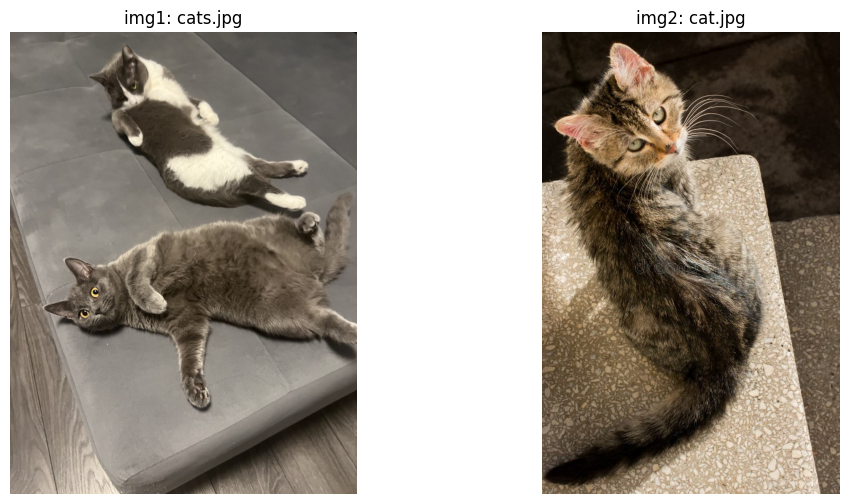

In [14]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, title in zip(axs, [img1, img2], ["img1: cats.jpg", "img2: cat.jpg"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 5. Люди и арены

- Человеческая оценка — золотой стандарт (особенно если опрашиваем целевую аудиторию), но самая дорогая
- Протокол SBS: один промпт, две анонимные картинки, варианты «левая / правая / ничья / обе плохие» ([GenAI-Arena](https://arxiv.org/abs/2406.04485))
- Из попарных голосов строят рейтинг:
  - онлайн-Elo чувствителен к порядку голосов
  - поэтому используют Bradley-Terry (логистическая MLE), ничьи делят пополам
- Публичные арены:
  - GenAI-Arena (TIGER-Lab)
  - Text-to-Image Arena у LMArena
  - [Artificial Analysis Image Arena](https://huggingface.co/spaces/ArtificialAnalysis/Text-to-Image-Leaderboard)
  - рейтинги меняются, поэтому конкретные позиции в лекции не фиксируем
- На чём экономят: VLM-судьи предсказывают голоса арены лишь частично (GPT-4o ≈49% средняя точность на GenAI-Arena) → людей они дополняют, а не заменяют

# Autoregressive

## 1. Формальная постановка и решение

Пусть имеется пространство объектов $x \in \mathcal{X}$, и дана выборка
$$
\mathcal{D} = {x^{(1)}, x^{(2)}, \dots, x^{(N)}}
$$
состоящая из независимых наблюдений, порожденных неизвестным распределением данных $p_{\mathrm{data}}(x)$

Задача состоит в том, чтобы построить параметрическое распределение
$$
p_\theta(x)
$$
которое хорошо аппроксимирует $p_{\mathrm{data}}(x)$

Пусть $x = (x_1, x_2, \dots, x_T)$, то есть нам нужно моделировать $p_\theta(x_1, x_2, \dots, x_T)$

**maximum likelihood estimation**

Требуется выбрать параметры $\theta$, максимизирующие правдоподобие обучающей выборки:

$$
\theta^\star = \arg\max_\theta \prod_{n=1}^{N} p_\theta\bigl(x^{(n)}\bigr)
$$

$$
\theta^\star = \arg\max_\theta \sum_{n=1}^{N} \log p_\theta\bigl(x^{(n)}\bigr)
$$

Эквивалентная задача минимизации отрицательного логарифмического правдоподобия:

$$
\theta^\star = \arg\min_\theta \left(- \sum_{n=1}^{N} \log p_\theta\bigl(x^{(n)}\bigr)\right)
$$

Если усреднить по выборке, получаем функцию потерь

$$
\mathcal{L}(\theta) = -\frac{1}{N} \sum_{n=1}^{N} \log p_\theta\bigl(x^{(n)}\bigr)
$$


---


**Autoregressive modeling**

Напрямую моделировать совместное распределение
$$
p_\theta(x_1, x_2, \dots, x_T)
$$
обычно трудно

Идея авторегрессионного подхода состоит в том, чтобы не моделировать совместное распределение напрямую, а разложить его на произведение более простых условных распределений.

Для любых случайных величин $x_1, x_2, \dots, x_T$ справедливо:
$$
p(x_1, x_2, \dots, x_T) = p(x_1) p(x_2 \mid x_1) p(x_3 \mid x_1, x_2)\cdots p(x_T \mid x_1, \dots, x_{T-1})
$$

В компактной записи:
$$
p(x_{1:T}) = \prod_{t=1}^{T} p(x_t \mid x_{<t})
$$
где
$$
x_{<t} = (x_1, x_2, \dots, x_{t-1})
$$

Тогда параметрическая модель записывается как
$$
p_\theta(x_{1:T}) = \prod_{t=1}^{T} p_\theta(x_t \mid x_{<t})
$$


Для каждого объекта выборки:

$$p_\theta\bigl(x^{(n)}_{1:T}\bigr) = \prod_{t=1}^{T} p_\theta\bigl(x^{(n)}_t \mid x^{(n)}_{<t}\bigr)$$


**Подставляем в MLE-задачу:**
$$
\max_\theta \sum_{n=1}^{N} \log \prod_{t=1}^{T} p_\theta\bigl(x^{(n)}_t \mid x^{(n)}_{<t}\bigr)
$$

Используем свойство $\log \prod a_t = \sum \log a_t$:
$$
\max_\theta \sum_{n=1}^{N} \sum_{t=1}^{T}
\log p_\theta\bigl(x^{(n)}_t \mid x^{(n)}_{<t}\bigr).
$$

Эквивалентно, минимизируем
$$
\mathcal{L}(\theta)=-\sum_{n=1}^{N} \sum_{t=1}^{T}
\log p_\theta\bigl(x^{(n)}_t \mid x^{(n)}_{<t}\bigr)
$$

Задача сводится к набору задач предсказания следующего элемента по предыдущим:
$$
x_{<t} \mapsto p_\theta(x_t \mid x_{<t})
$$

**Markov assuption**

Для больших $t$ вычисление $p_\theta(x_t \mid x_{<t})$ может быть очень дорогим. Поэтому мы делаем доп предположение марковости

$$
p_\theta(x_t \mid x_{<t}) = p_\theta(x_t \mid x_{t-d:t-1})
$$

где $d$ - фиксированнные параметр

---

## 2. Примеры архитектур

### 1. PixelCNN — авторегрессия по пикселям (2016)

[Arxiv](https://arxiv.org/abs/1601.06759) — van den Oord et al., "Pixel Recurrent Neural Networks" (PixelRNN / PixelCNN)

*Идея:*
- Изображение — последовательность пикселей в порядке raster scan (слева направо, сверху вниз): $p(x) = \prod_i p(x_i \mid x_{<i})$
- Каждое значение цвета — дискретное: softmax на 256 классов
- Каналы внутри пикселя тоже авторегрессионны: $p(x_i) = p(x_{i,R} \mid x_{<i})\, p(x_{i,G} \mid x_{<i}, x_{i,R})\, p(x_{i,B} \mid x_{<i}, x_{i,R}, x_{i,G})$

*Masked convolution:*
- Обычная свёртка видит пиксели справа и снизу — это нарушает авторегрессионность
- Mask A (первый слой): скрывает текущий пиксель и всё «будущее»
- Mask B (последующие слои): разрешает центр, т.к. признаки в нём уже не зависят от самого пикселя
- На обучении все условные распределения считаются **за один параллельный проход** (teacher forcing)

*Сэмплирование:*
- Строго последовательное: один шаг на каждый пиксель и канал
- Для RGB 256×256: $256 \cdot 256 \cdot 3 \approx 200$ k шагов

*Почему отказались:*
- Очень медленное сэмплирование
- Растровый порядок неестественен для картинок
- Слабый глобальный контекст (ограниченное рецептивное поле)

Вывод: нужны токены крупнее пикселя и порядок, естественный для картинок

Маски и порядок генерации (картинки из статьи):

![maska](./assets/pixelcnn-maska.png)

![masks](./assets/pixelcnn-convs.png)

![pix-infer](./assets/pixelcnn-order.png)

![pix-rgb](./assets/pixelcnn-rgb.png)

### 2. От пикселей к токенам

*Токенизатор (VQ-VAE / VQGAN):*
- Encoder сжимает картинку в карту латентов
- Каждый латент заменяется ближайшим вектором из codebook → получаем индекс (дискретный токен)
- Decoder восстанавливает картинку по векторам codebook
- Картинка 256×256 → карта 16×16 = **256 дискретных токенов**
- Это тот же VAE / VQ-VAE из лекции 8

*Генератор:*
- Обычный decoder-only трансформер, next-token prediction, cross-entropy по словарю codebook — «рецепт LLM»
- Пример: LlamaGen ([Arxiv](https://arxiv.org/abs/2406.06525)) — архитектура Llama на VQ-токенах, токенизатор с downsample 16, class- и text-conditional генерация

*Что осталось плохо:*
- Растровый порядок по-прежнему неестественен для картинок
- 256 последовательных шагов
- Квантизация теряет детали

### 3. VAR: Visual Autoregressive Modeling (Tian et al., NeurIPS 2024, best paper)

[GitHub](https://github.com/FoundationVision/VAR) · [Arxiv](https://arxiv.org/pdf/2404.02905)

![](https://github.com/FoundationVision/VAR/assets/39692511/3e12655c-37dc-4528-b923-ec6c4cfef178)

#### Проблема next-token подхода

- Растровый порядок неестественен для картинок: соседи по вертикали далеко друг от друга в последовательности, глобальная структура решается последней.
- Шагов генерации столько, сколько токенов: 256 для карты 16×16, каждый ждёт предыдущего.

#### Идея

Сменить единицу предсказания: не **следующий токен**, а **следующий масштаб** — вся карта токенов более высокого разрешения целиком.

$$
p(r_1, \dots, r_K) = \prod_{k=1}^{K} p(r_k \mid r_1, \dots, r_{k-1})
$$

- $r_k$ — карта токенов масштаба $k$ размера $h_k \times w_k$.
- Авторегрессия по масштабам, внутри масштаба все токены предсказываются **параллельно**.
- От грубого к точному: сначала глобальная структура, потом детали. $K = 10$ шагов вместо 256.

#### Общая схема: два этапа

| этап | модель | что делает | loss |
|---|---|---|---|
| 1 | токенизатор | картинка ↔ токены на $K$ масштабах | реконструкция (как VQGAN) |
| 2 | трансформер | по классу и масштабам $1..k{-}1$ предсказать $r_k$ | cross-entropy по токенам |

Токенизатор обучается первым и замораживается. Трансформер никогда не видит пикселей, только токены.

---

#### Этап 1. Токенизатор: multi-scale residual VQ

**Пирамида масштабов.** Энкодер сжимает картинку 256×256 в латентную карту $f \in \mathbb{R}^{16 \times 16 \times C}$. Её кодируют в $K = 10$ разрешениях:

```
1×1   2×2   3×3   4×4   5×5   6×6   8×8   10×10   13×13   16×16
```

Масштаб $k$ — карта $h_k \times w_k$ токенов: 1, 4, 9, …, 256. Всего 680.

**Остатки.** Каждый масштаб хранит только то, что не объяснили предыдущие:

```
f  = Encoder(image)                           # 16×16×C
f̂  = 0                                        # накопленное восстановление
for k in 1..K:
    r_k = Quantize( resize(f, h_k×w_k) )          # уменьшить; каждая клетка → номер ближайшего вектора codebook
    z_k = φ_k( resize( lookup(r_k), 16×16 ) )     # номера → векторы, растянуть до 16×16, сгладить
    f  = f − z_k                                  # остаток: что ещё не объяснено
    f̂  = f̂ + z_k
image ≈ Decoder(f̂)
```

- **Codebook** общий для всех масштабов: $V = 4096$ векторов размерности $C$.
- **resize** — билинейная интерполяция. Чтобы складывать карты разных размеров, каждую растягивают до 16×16: один вектор масштаба 1×1 размазывается на все 256 клеток, четыре вектора масштаба 2×2 — на четверти с плавными переходами, и так далее.
- **$\phi_k$** — свёртка 3×3, своя на масштаб, убирает размытие интерполяции. Все вместе ≈0.03M параметров.
- Разделение по масштабам никто не задаёт руками: масштаб 1 — единственный, кто может объяснить низкие частоты всей карты одним вектором, каждый следующий берёт оставшееся.

**Loss** — как у VQGAN:

$$
\mathcal{L}_{\text{tok}} = \underbrace{\mathcal{L}_{\text{rec}} + \mathcal{L}_{\text{perc}} + \mathcal{L}_{\text{GAN}}}_{\text{на итоговом } \hat x = \text{Decoder}(\sum_k z_k)} + \underbrace{\sum_{k} \mathcal{L}_{\text{commit}}^{(k)}}_{\text{на каждой квантизации}}
$$

Реконструкция сравнивается с картинкой **только после суммы всех масштабов**, промежуточные версии ни с чем не сравниваются. Градиент через `argmin` — straight-through.

Архитектура энкодера, декодера и loss — от VQGAN, но обучается всё заново, с многомасштабной квантизацией внутри: готовый декодер VQGAN не умеет читать сумму растянутых остатков. После этапа 1 замораживаются все части: энкодер, codebook, $\phi_k$, декодер.

**Следствие:** качество генерации ограничено сверху качеством реконструкции токенизатора — потерянные им детали трансформер не вернёт.

Визуализация обучения (скрин из статьи)

![](./assets/var-screen.jpg)

---

#### Этап 2. Трансформер

**Вход и ответ.** Как в GPT, у каждой позиции есть вход и ответ, который она должна предсказать. Ответ позиций масштаба $k$ — токены $r_k$. Вход — **черновик**: сумма остатков предыдущих масштабов $\hat f_{k-1} = \sum_{j<k} z_j$ (карта 16×16), **уменьшенная** до $h_k \times w_k$.

```
масштаб 1 (1 позиция):    вход  [s] = эмбеддинг класса y            →  ответ r_1
масштаб 2 (4 позиции):    вход  word_embed( resize(f̂_1, 2×2) )       →  ответ r_2
масштаб 3 (9 позиций):    вход  word_embed( resize(f̂_2, 3×3) )       →  ответ r_3
...
масштаб 10 (256 позиций): вход  word_embed( resize(f̂_9, 16×16) )     →  ответ r_10
```

- На масштабе 1 черновика ещё нет, вместо него — **эмбеддинг класса**: обучаемая таблица 1000 классов ImageNet (+1 «пустой» для CFG), как эмбеддинги слов в LLM.
- `word_embed` — линейный слой $C \to$ ширина модели.
- К каждому входу прибавляются обучаемый **позиционный** эмбеддинг (свой на каждую из 680 позиций) и эмбеддинг **уровня** (один на масштаб).

**Что выдаёт трансформер.** Для каждой позиции — **4096 логитов**, по одному на вектор codebook. После softmax это распределение: «с какой вероятностью в этой клетке стоит слово номер 1, …, номер 4096». На обучении это распределение сравнивается с настоящим номером, на генерации из него выбирается номер.

**Block-wise causal mask.** Позиция масштаба $k$ видит входы масштабов $\le k$ и не видит масштабы $> k$.

- *Почему соседей по своему масштабу видеть можно:* их входы — куски того же черновика из масштабов $< k$, ответов $r_k$ в них нет.
- *Почему старшие масштабы видеть нельзя:* во вход масштаба $k{+}1$ уже вшит ответ $r_k$ — это подглядывание.

**Архитектура** — GPT-2 с AdaLN из DiT:

- блок: pre-norm self-attention + FFN (расширение ×4, GELU);
- **условие на класс** входит дважды: как $[s]$ на масштабе 1 и через **AdaLN** в каждом блоке — сдвиг, масштаб и гейт нормализации вычисляются из эмбеддинга класса;
- выход: LayerNorm + линейный слой в 4096 логитов, голова общая для всех масштабов;
- размер: глубина $d$, ширина $64d$, $d$ голов. d16 — 310M, d20 — 600M, d24 — 1.0B, d30 — 2.0B;
- нет cross-attention (условие только класс), нет RoPE (позиций конечное число), нет отдельных слоёв под масштабы.

Текста в VAR нет — только классы ImageNet. Текст появится у наследников через текстовый энкодер и cross-attention (Switti, Infinity).

---

#### Обучение трансформера: один проход

Все $r_k$ уже посчитаны замороженным токенизатором, поэтому все 680 входов собираются заранее из **настоящих** токенов (teacher forcing):

```
inputs = [ class_emb(y) + pos_1 ]                  # вход масштаба 1
f̂ = 0
for k in 1..K−1:
    z_k = φ_k( resize( lookup(r_k), 16×16 ) )      # настоящий r_k → остаток
    f̂  = f̂ + z_k                                   # черновик из настоящих масштабов 1..k
    inputs += word_embed( resize(f̂, h_{k+1}×w_{k+1}) ) + pos + level_{k+1}

logits = Transformer(inputs, block_causal_mask)    # 680 позиций → 680 × 4096 логитов
loss   = CrossEntropy(logits, [r_1, ..., r_K])
```

$$
\mathcal{L}_{\text{AR}} = -\sum_{k=1}^{K} \sum_{(i,j) \in h_k \times w_k} \log p_\theta\big(r_k[i,j] \mid y,\ r_1, \dots, r_{k-1}\big)
$$

Каждый масштаб учится отвечать на вопрос «если предыдущие масштабы правильные, какой следующий?». Собственные предсказания в цепочку не подставляются: это дало бы 10 последовательных проходов вместо одного, а в начале обучения входы были бы мусорными. Класс с вероятностью 0.1 заменяется на «пустой» — для CFG.

#### Генерация: K проходов

Теперь $r_k$ появляется только после прохода $k$, поэтому последовательность растёт:

```
f̂ = 0
inputs = [ class_emb(y) + pos_1 ]
for k in 1..K:
    logits = Transformer(inputs)                   # h_k·w_k новых позиций, старые — в KV-cache
    logits = (1+w)·logits_cond − w·logits_uncond   # CFG, w = 2.0
    r_k    = Sample(logits)                        # ← единственное отличие от обучения
    z_k    = φ_k( resize( lookup(r_k), 16×16 ) )
    f̂      = f̂ + z_k
    inputs += word_embed( resize(f̂, h_{k+1}×w_{k+1}) ) + pos + level_{k+1}
image = Decoder(f̂)
```

- **Sample** — выбор номера из распределения, как в LLM: top-k (в коде ещё top-p). Argmax дал бы одинаковые «усреднённые» картинки, чистый random — артефакты от маловероятных номеров.
- Каждая позиция масштаба сэмплируется **независимо**: структура задана черновиком, масштаб добавляет поправку.
- Маска не нужна: будущих масштабов в последовательности ещё нет.
- Сборка входа — та же, что на обучении, но из сэмплированных токенов. Отсюда **exposure bias**: модель получает черновики, которых на обучении не видела; смягчён тем, что шагов всего 10.

#### Сложность

Карта $n \times n$ токенов (Appendix B статьи):

| | шагов | вычислений |
|---|---|---|
| next-token AR | $O(n^2)$ | $O(n^6)$ |
| VAR | $O(\log n)$ | $O(n^4)$ |

#### Результаты

- ImageNet 256×256: FID 1.73 (VAR-d30, 2B, с rejection sampling; 1.92 без), IS 350.
- Инференс ≈20× быстрее next-token AR (по аннотации статьи).
- **Scaling laws:** 12 моделей от 18M до 2B, loss падает по степенному закону, Пирсон ≈ −0.998. Авторегрессия на картинках масштабируется так же предсказуемо, как LLM.
- Zero-shot in-/out-painting и редактирование: фиксируем известные токены на всех масштабах, досэмплируем остальные (показано качественно).

#### Ограничения

- Квантизация теряет детали → **Infinity** (побитовые токены, словарь до $2^{64}$), **HART** (диффузия для непрерывного остатка).
- Токены внутри масштаба условно независимы → возможны несогласованные детали.
- Exposure bias → Infinity добавляет bitwise self-correction: при обучении в токены предыдущих масштабов специально вносят ошибки.
- Набор масштабов зашит в токенизатор: другое разрешение — другой токенизатор.

In [ ]:
## download var
# !git clone --filter=blob:none --no-checkout https://github.com/FoundationVision/VAR.git .var && cd .var && git sparse-checkout init --cone && git sparse-checkout set models && git checkout

In [ ]:
import sys

sys.path.append(".var")

In [ ]:
# code from https://github.com/FoundationVision/VAR/blob/main/demo_sample.ipynb

################## 1. Download checkpoints and build models
import os
import os.path as osp
import torch, torchvision
import random
import numpy as np
import PIL.Image as PImage, PIL.ImageDraw as PImageDraw
setattr(torch.nn.Linear, 'reset_parameters', lambda self: None)     # disable default parameter init for faster speed
setattr(torch.nn.LayerNorm, 'reset_parameters', lambda self: None)  # disable default parameter init for faster speed
from models import VQVAE, build_vae_var

MODEL_DEPTH = 16    # TODO: =====> please specify MODEL_DEPTH <=====
assert MODEL_DEPTH in {16, 20, 24, 30}


# download checkpoint
hf_home = 'https://huggingface.co/FoundationVision/var/resolve/main'
vae_ckpt, var_ckpt = 'vae_ch160v4096z32.pth', f'var_d{MODEL_DEPTH}.pth'
if not osp.exists(vae_ckpt): os.system(f'wget {hf_home}/{vae_ckpt}')
if not osp.exists(var_ckpt): os.system(f'wget {hf_home}/{var_ckpt}')

# build vae, var
patch_nums = (1, 2, 3, 4, 5, 6, 8, 10, 13, 16)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
if 'vae' not in globals() or 'var' not in globals():
    vae, var = build_vae_var(
        V=4096, Cvae=32, ch=160, share_quant_resi=4,    # hard-coded VQVAE hyperparameters
        device=device, patch_nums=patch_nums,
        num_classes=1000, depth=MODEL_DEPTH, shared_aln=False,
    )

# load checkpoints
vae.load_state_dict(torch.load(vae_ckpt, map_location='cpu'), strict=True)
var.load_state_dict(torch.load(var_ckpt, map_location='cpu'), strict=True)
vae.eval(), var.eval()
for p in vae.parameters(): p.requires_grad_(False)
for p in var.parameters(): p.requires_grad_(False)
print(f'prepare finished.')


[constructor]  ==== flash_if_available=True (0/16), fused_if_available=True (fusing_add_ln=0/16, fusing_mlp=0/16) ==== 
    [VAR config ] embed_dim=1024, num_heads=16, depth=16, mlp_ratio=4.0
    [drop ratios ] drop_rate=0.0, attn_drop_rate=0.0, drop_path_rate=0.0666667 (tensor([0.0000, 0.0044, 0.0089, 0.0133, 0.0178, 0.0222, 0.0267, 0.0311, 0.0356,
        0.0400, 0.0444, 0.0489, 0.0533, 0.0578, 0.0622, 0.0667]))

[init_weights] VAR with init_std=0.0180422
prepare finished.


/var/folders/lv/42595jc551g9q6l8b96ktvs40000gq/T/ipykernel_49006/3341413505.py:28: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.autocast('cuda', enabled=True, dtype=torch.float16, cache_enabled=True):    # using bfloat16 can be faster


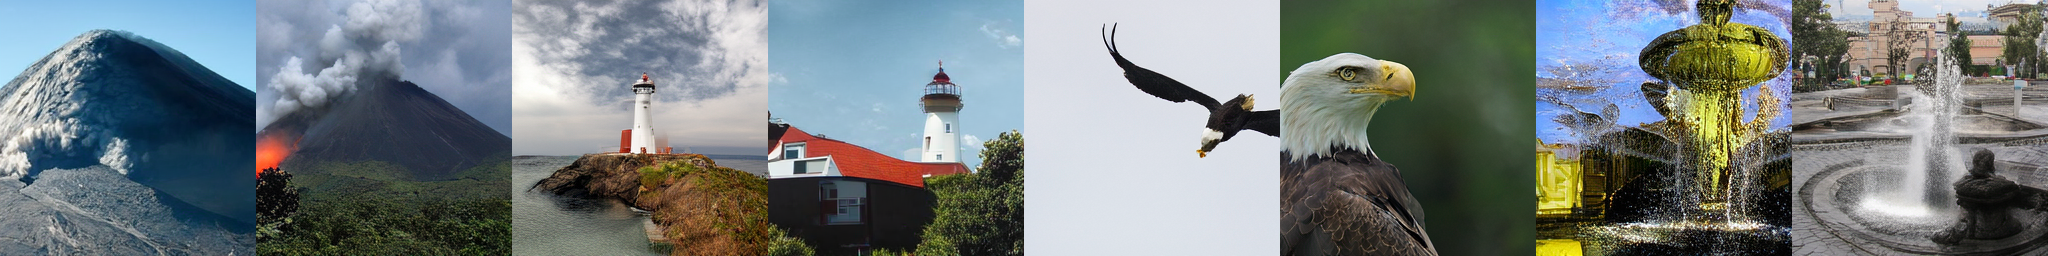

In [ ]:
############################# 2. Sample with classifier-free guidance

# set args
seed = 0 #@param {type:"number"}
torch.manual_seed(seed)
num_sampling_steps = 250 #@param {type:"slider", min:0, max:1000, step:1}
cfg = 4 #@param {type:"slider", min:1, max:10, step:0.1}
class_labels = (980, 980, 437, 437, 22, 22, 562, 562)  #@param {type:"raw"}
more_smooth = False # True for more smooth output

# seed
torch.manual_seed(seed)
random.seed(seed)
np.random.seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# run faster
tf32 = True
torch.backends.cudnn.allow_tf32 = bool(tf32)
torch.backends.cuda.matmul.allow_tf32 = bool(tf32)
torch.set_float32_matmul_precision('high' if tf32 else 'highest')

# sample
B = len(class_labels)
label_B: torch.LongTensor = torch.tensor(class_labels, device=device)
with torch.inference_mode():
    with torch.autocast('cuda', enabled=True, dtype=torch.float16, cache_enabled=True):    # using bfloat16 can be faster
        recon_B3HW = var.autoregressive_infer_cfg(B=B, label_B=label_B, cfg=cfg, top_k=900, top_p=0.95, g_seed=seed, more_smooth=more_smooth)

    chw = torchvision.utils.make_grid(recon_B3HW, nrow=8, padding=0, pad_value=1.0)
    chw = chw.permute(1, 2, 0).mul_(255).cpu().numpy()
    chw = PImage.fromarray(chw.astype(np.uint8))

chw

### 4. Switti: что меняется относительно VAR (Voronov et al., CVPR 2025)

[GitHub](https://github.com/yandex-research/switti) · [Arxiv](https://arxiv.org/pdf/2412.01819)

VAR для text-to-image. Та же схема «multi-scale residual VQ + трансформер по масштабам», отличия ниже.

| | VAR | Switti |
|---|---|---|
| условие | класс ImageNet: $[s]$ + AdaLN | текст: два энкодера — CLIP ViT-L и OpenCLIP ViT-bigG, эмбеддинги конкатенируются; подаются через **cross-attention** (между self-attention и FFN в каждом блоке); pooled-эмбеддинг — через AdaLN |
| маска внимания | block-wise causal: масштаб $k$ видит масштабы $\le k$ | **маски нет**: каждый масштаб смотрит только внутрь себя, информация о предыдущих масштабах приходит только через черновик на входе → ≈21% быстрее, KV-cache не нужен |
| CFG | на всех масштабах | **выключен на последних масштабах** высокого разрешения: там он почти не влияет на результат, а стоит второй forward → ещё ≈32% ускорения |
| блок трансформера | GPT-2: LayerNorm, GELU, обучаемые позиции | RMSNorm + sandwich-norm, SwiGLU, нормализованный 2D RoPE; crop-conditioning как в SDXL |
| токенизатор | обучается целиком | энкодер RQ-VAE заморожен, дообучен только декодер под 512×512 |

![](https://raw.githubusercontent.com/yandex-research/switti/refs/heads/master/assets/teaser.jpg)

In [ ]:
# %%bash

# !git clone https://github.com/yandex-research/switti.git .switti

# cat > .switti/utils/arg_util.py << 'EOF'
# RESOLUTION_PATCH_NUMS_MAPPING = {
#     256: "1_2_3_4_5_6_8_10_13_16",
#     512: "1_2_3_4_6_9_13_18_24_32",
#     1024: "1_2_3_4_5_7_9_12_16_21_27_36_48_64",
# }
# EOF

# # pip install -r .switti/requirements.txt

In [ ]:
# # one need to restart since it conflicts with var
# import sys
# sys.path.append(".switti")

# import torch

# from models import SwittiPipeline

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# model_path = "yresearch/Switti"
# dtype = torch.bfloat16 if DEVICE.type != 'cpu' else torch.float32

# pipe = SwittiPipeline.from_pretrained(model_path, device=DEVICE, torch_dtype=dtype, reso=512)

# from torchvision.utils import make_grid
# from torchvision.transforms.functional import to_pil_image

# prompts = ["Cute winter dragon baby, kawaii, Pixar, ultra detailed, glacial background, extremely realistic",
#            "flying robot koi fish with armour plating, neon glowing eyes and wiring, 4k, unreal engine, marvel comics style",
#            "sci-fi cosmic diarama of a quasar and jellyfish in a resin cube, volumetric lighting, high resolution, hdr, sharpen, Photorealism",
#            "A cloud dragon flying over mountains, its body swirling with the wind.",
#           ]
# images = pipe(prompts,
#               cfg=6.0,
#               top_k=400,
#               top_p=0.95,
#               more_smooth=True,
#               return_pil=False,
#               smooth_start_si=2,
#               turn_on_cfg_start_si=2,
#               turn_off_cfg_start_si=8,
#               last_scale_temp=0.1,
#               seed=59,
#              )
# to_pil_image(make_grid([img.float() for img in images], nrow=2))

### 5. Infinity: что меняется относительно VAR (Han et al., CVPR 2025)

[GitHub](https://github.com/FoundationVision/Infinity) · [Arxiv](https://arxiv.org/abs/2412.04431)

Та же команда, что и VAR. Цель — text-to-image в высоком разрешении (1024×1024) и борьба с главным ограничением VAR: потерей деталей при квантизации.

| | VAR | Infinity |
|---|---|---|
| токен | номер в codebook из $V = 4096$ векторов | **побитовый**: токен = $d$ бит, словарь $2^d$ — до $2^{32}$ и $2^{64}$. Codebook как таблицы векторов больше нет, вектор восстанавливается из битов |
| выход трансформера | softmax по 4096 классам | **infinite-vocabulary classifier**: предсказывает $d$ бит независимо ($d$ сигмоид) вместо softmax по $2^d$ классам — иначе голова не поместилась бы в память |
| exposure bias | не решается | **bitwise self-correction**: при обучении в токены предыдущих масштабов случайно переворачивают биты и заново считают остаток — модель учится исправлять собственные ошибки |
| условие | класс | текст через текстовый энкодер и cross-attention |
| результат | ImageNet 256 | 1024×1024 за ≈0.8 с; GenEval 0.73 против 0.62 у SD3-Medium, win rate 66% (цифры авторов) |

### 6. Современные AR-модели (2024–2026): три ветки

После VAR авторегрессионная генерация изображений развивается в трёх направлениях: масштабирование next-token на дискретных токенах, развитие next-scale, отказ от квантизации в пользу непрерывных токенов (часто с диффузионной головой).

| ветка | модель | год | токены | порядок генерации | особенность |
|---|---|---|---|---|---|
| (а) next-token, дискретные | LlamaGen ([2406.06525](https://arxiv.org/abs/2406.06525)) | 2024 | дискретные VQ | next-token, растр | «рецепт LLM» для картинок, ImageNet FID 2.18 |
| (а) next-token, дискретные | Emu3 ([2409.18869](https://arxiv.org/abs/2409.18869)) | 2024 | дискретные | next-token | генерация изображений чистым next-token на дискретных токенах, без диффузии |
| (а) next-token, дискретные | TensorAR ([2505.16324](https://arxiv.org/abs/2505.16324)) | 2025 | дискретные | next-tensor, скользящие окна патчей | предсказывает тензор патчей с перекрытием → может уточнять уже сгенерированное; plug-in к LlamaGen и др. |
| (б) next-scale (линия VAR) | VAR ([2404.02905](https://arxiv.org/abs/2404.02905)) | 2024 | дискретные multi-scale | next-scale | см. выше |
| (б) next-scale (линия VAR) | Switti ([2412.01819](https://arxiv.org/abs/2412.01819)) | 2024, CVPR 2025 | дискретные multi-scale | next-scale | text-to-image на базе VAR, см. выше |
| (б) next-scale (линия VAR) | Infinity ([2412.04431](https://arxiv.org/abs/2412.04431), [Github](https://github.com/FoundationVision/Infinity)) | 2024, CVPR 2025 | побитовые multi-scale, словарь до $2^{64}$ | next-scale | «infinite-vocabulary» classifier предсказывает биты, bitwise self-correction; 1024² за ~0.8 с (по статье) |
| (в) непрерывные / гибриды с диффузией | MAR ([2406.11838](https://arxiv.org/abs/2406.11838)) | 2024 | непрерывные, без VQ | AR / masked AR | распределение токена задаёт маленькая диффузионная голова (diffusion loss) |
| (в) непрерывные / гибриды с диффузией | HART ([2410.10812](https://arxiv.org/abs/2410.10812)) | 2024 | дискретные + непрерывный остаток | next-scale | гибрид: VAR-подобные токены + диффузия (~37M) для остатка; 1024² |
| (в) непрерывные / гибриды с диффузией | NextStep-1 ([2508.10711](https://arxiv.org/abs/2508.10711)) | 2025 | непрерывные | next-token | 14B AR + flow-matching голова 157M, T2I и редактирование |
| (в) непрерывные / гибриды с диффузией | LINA ([2601.22630](https://arxiv.org/abs/2601.22630)) | 2026 | непрерывные | next-token | линейное внимание для AR с непрерывными токенами, FID 2.18 ImageNet при ~1.4B |

*Takeaway:* ветка (в) сближает AR и диффузию — токены генерируются авторегрессионно, а распределение внутри токена моделирует диффузия / flow matching. Это мостик к разделу про диффузионные модели.